# OGLE targets on the Rubin DP2 coverage map

This standalone notebook reads `OGLE_test.csv`, queries DP2 directly through the RSP TAP service, and plots the targets over a background showing the number of DP2 detector images. It does not use `target_selection` or `mop_api`.


## 1. Settings and imports

The TAP query uses detector-center positions from `dp2.VisitDetector`. Each row represents one visit/detector image. The coverage background is displayed as a hexagonal binned map.


In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from lsst.rsp import RSPDiscovery

CSV_PATH = Path("../OGLE_test.csv") if (Path.cwd() / "../OGLE_test.csv").exists() else Path("OGLE_test.csv")
OUTPUT_DIR = Path("../outputs/ogle_dp2_coverage") if (Path.cwd() / "../outputs").exists() else Path("outputs/ogle_dp2_coverage")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RSP_INSTANCE = "dp2"
VISIT_TABLE = "dp2.VisitDetector"
REGION_MARGIN_DEG = 1.0
HEXBIN_GRIDSIZE = 160


## 2. Load and normalize the OGLE targets

The input file contains `Event`, `RA_deg`, and `Dec_deg`. The event names are converted to the conventional `OGLE-...` form when needed.


In [11]:
targets = pd.read_csv(
    CSV_PATH,
    comment="#",
    skipinitialspace=True,
)
targets.columns = targets.columns.astype(str).str.strip()
targets = targets.rename(columns={"Event": "Target"})
for column in ("Target", "RA_deg", "Dec_deg"):
    if column not in targets.columns:
        raise ValueError(f"Missing required column: {column}")

targets["Target"] = targets["Target"].astype(str).str.strip()
targets["Target"] = targets["Target"].map(
    lambda name: name if name.upper().startswith("OGLE-") else f"OGLE-{name}"
)
targets["RA_deg"] = pd.to_numeric(targets["RA_deg"], errors="coerce")
targets["Dec_deg"] = pd.to_numeric(targets["Dec_deg"], errors="coerce")
targets = targets.dropna(subset=["RA_deg", "Dec_deg"]).drop_duplicates("Target")

print(f"Targets loaded: {len(targets)}")
targets.head()


Targets loaded: 205


,Target,Tmax_UT,RA_deg,Dec_deg
0,OGLE-2025-BLG-0137,2025-08-07.81,266.317792,-35.203250
1,OGLE-2025-BLG-0138,2025-08-08.67,266.317625,-35.203167
2,OGLE-2025-BLG-0214,2025-07-30.46,262.363667,-30.065278
3,OGLE-2025-BLG-0233,2025-07-30.49,274.101875,-18.281750
4,OGLE-2025-BLG-0260,2025-07-23.72,269.282583,-30.915222


## 3. Query DP2 detector coverage

The query is limited to the rectangular region containing the targets. The margin can be increased for a wider map.


In [12]:
tap_service = RSPDiscovery(RSP_INSTANCE).get_tap_client()

ra_min, ra_max = targets["RA_deg"].min(), targets["RA_deg"].max()
dec_min, dec_max = targets["Dec_deg"].min(), targets["Dec_deg"].max()

coverage_query = f"""
SELECT vd.ra, vd.dec, vd.visitId, vd.detector, vd.band, vd.expMidptMJD
FROM {VISIT_TABLE} AS vd
WHERE vd.ra BETWEEN {ra_min - REGION_MARGIN_DEG:.8f} AND {ra_max + REGION_MARGIN_DEG:.8f}
  AND vd.dec BETWEEN {dec_min - REGION_MARGIN_DEG:.8f} AND {dec_max + REGION_MARGIN_DEG:.8f}
"""

job = tap_service.submit_job(coverage_query)
job.run()
job.wait(phases=["COMPLETED", "ERROR"])
if job.phase == "ERROR":
    job.raise_if_error()

coverage = job.fetch_result().to_table().to_pandas()
coverage.columns = [str(column) for column in coverage.columns]
coverage.to_csv(OUTPUT_DIR / "dp2_visit_detector_coverage.csv", index=False)

print(f"DP2 detector rows: {len(coverage)}")
print(f"DP2 visits: {coverage['visitId'].nunique() if not coverage.empty else 0}")


DP2 detector rows: 546074
DP2 visits: 3626


## 4. Plot targets and DP2 image-count coverage

The background color represents the number of DP2 detector-image rows per spatial hexbin. Empty bins remain white. Target markers are plotted on top and labeled with their event names.


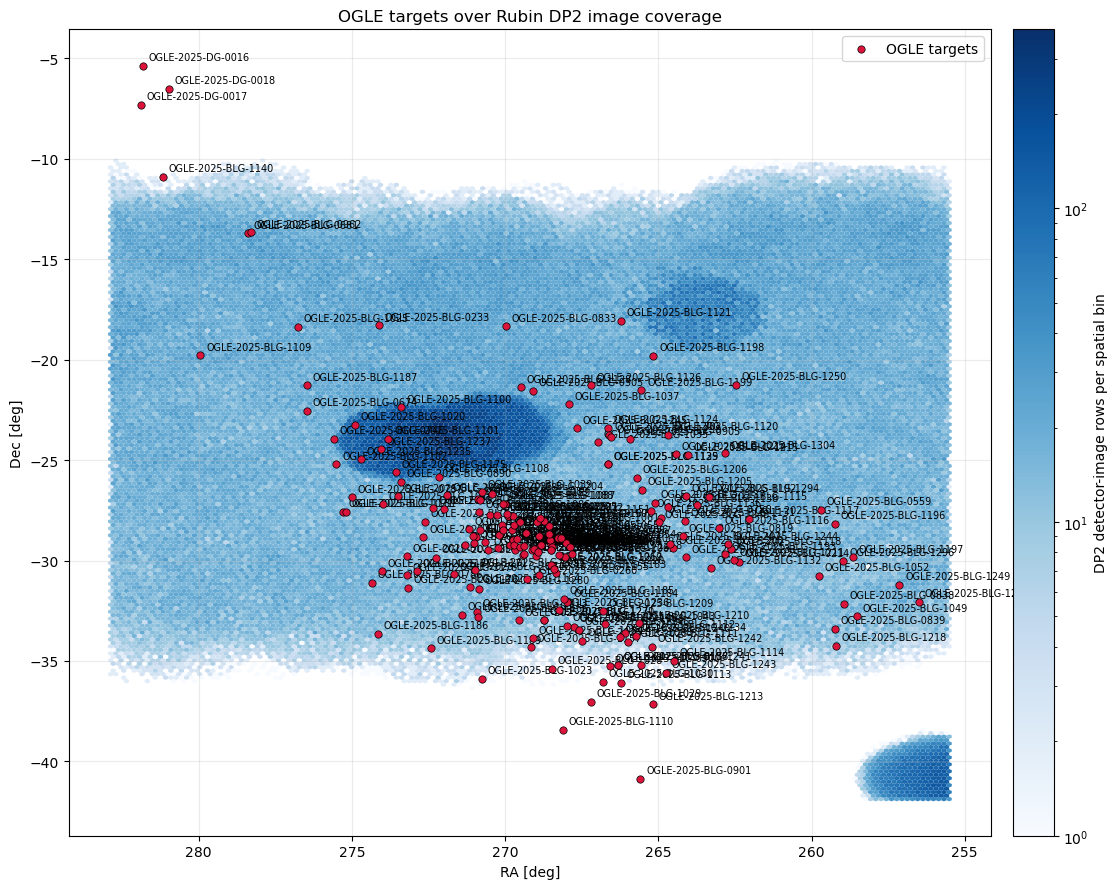

In [13]:
fig, ax = plt.subplots(figsize=(12, 9))

if coverage.empty:
    print("No DP2 detector rows were returned in the selected region.")
else:
    counts = ax.hexbin(
        coverage["ra"],
        coverage["dec"],
        gridsize=HEXBIN_GRIDSIZE,
        mincnt=1,
        bins="log",
        cmap="Blues",
        linewidths=0.0,
    )
    colorbar = fig.colorbar(counts, ax=ax, pad=0.02)
    colorbar.set_label("DP2 detector-image rows per spatial bin")

ax.scatter(
    targets["RA_deg"],
    targets["Dec_deg"],
    s=28,
    c="crimson",
    edgecolors="black",
    linewidths=0.5,
    zorder=5,
    label="OGLE targets",
)

for row in targets.itertuples(index=False):
    ax.annotate(
        row.Target,
        (row.RA_deg, row.Dec_deg),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
        color="black",
    )

ax.set_xlabel("RA [deg]")
ax.set_ylabel("Dec [deg]")
ax.set_title("OGLE targets over Rubin DP2 image coverage")
ax.invert_xaxis()
ax.grid(alpha=0.25)
ax.legend(loc="best")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ogle_targets_dp2_coverage.png", dpi=180, bbox_inches="tight")
plt.show()


## 5. Full DP2 sky footprint

This query aggregates `VisitDetector` on the TAP server, returning one sky position per visit. It is much smaller than downloading every detector row and shows the complete DP2 visit footprint.


DP2 visits in full footprint: 28698


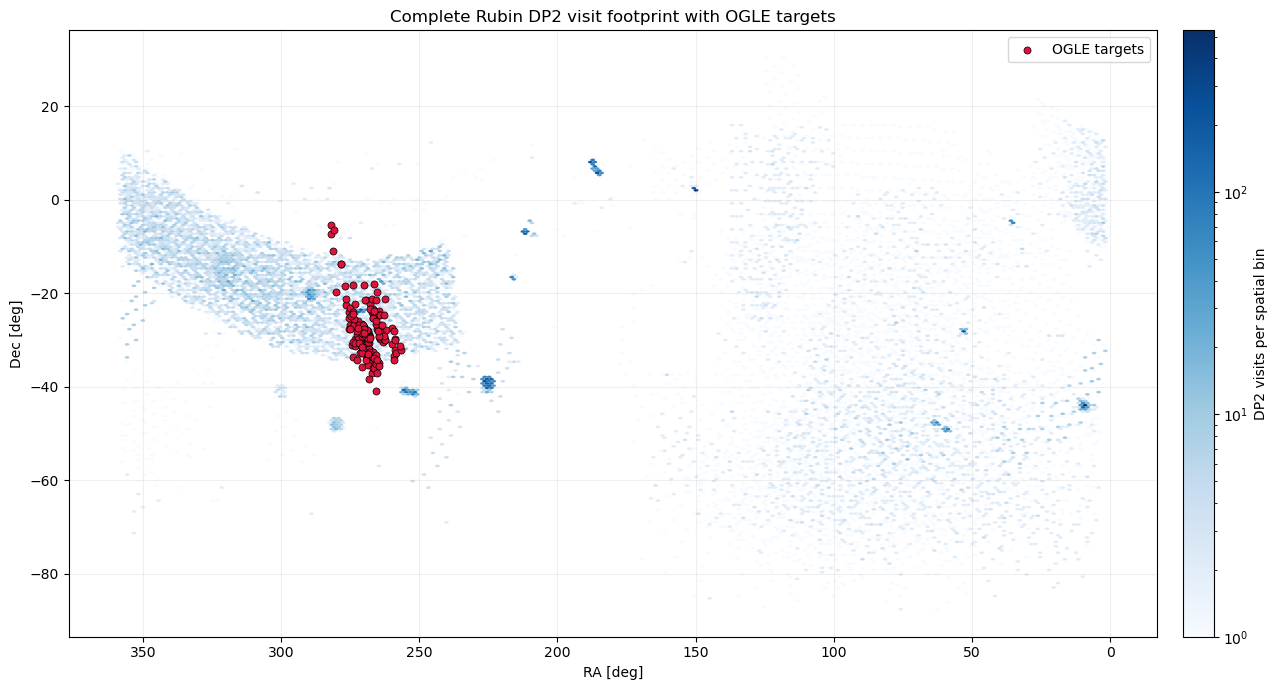

In [14]:
full_coverage_query = f"""
SELECT vd.visitId, AVG(vd.ra) AS ra, AVG(vd.dec) AS dec, COUNT(*) AS n_detectors
FROM {VISIT_TABLE} AS vd
GROUP BY vd.visitId
"""

full_job = tap_service.submit_job(full_coverage_query)
full_job.run()
full_job.wait(phases=["COMPLETED", "ERROR"])
if full_job.phase == "ERROR":
    full_job.raise_if_error()

full_coverage = full_job.fetch_result().to_table().to_pandas()
full_coverage.columns = [str(column) for column in full_coverage.columns]
full_coverage.to_csv(OUTPUT_DIR / "dp2_full_visit_footprint.csv", index=False)
print(f"DP2 visits in full footprint: {len(full_coverage)}")

fig, ax = plt.subplots(figsize=(14, 7))
footprint = ax.hexbin(
    full_coverage["ra"], full_coverage["dec"],
    gridsize=220, mincnt=1, bins="log", cmap="Blues",
    linewidths=0,
)
cb = fig.colorbar(footprint, ax=ax, pad=0.02)
cb.set_label("DP2 visits per spatial bin")

ax.scatter(
    targets["RA_deg"], targets["Dec_deg"],
    s=26, c="crimson", edgecolors="black", linewidths=.5,
    label="OGLE targets", zorder=5,
)
ax.set_xlabel("RA [deg]")
ax.set_ylabel("Dec [deg]")
ax.set_title("Complete Rubin DP2 visit footprint with OGLE targets")
ax.invert_xaxis()
ax.grid(alpha=.2)
ax.legend(loc="best")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "dp2_full_sky_footprint.png", dpi=180, bbox_inches="tight")
plt.show()


## 5. Coverage count at each target

This optional diagnostic counts detector-image rows within a small radius around each target. It is separate from the hexbin visualization.


In [15]:
TARGET_RADIUS_DEG = 0.05

if coverage.empty:
    target_counts = targets.assign(dp2_detector_image_count=0)
else:
    target_counts = []
    for row in targets.itertuples(index=False):
        separation2 = (coverage["ra"] - row.RA_deg) ** 2 + (coverage["dec"] - row.Dec_deg) ** 2
        target_counts.append({
            "Target": row.Target,
            "RA_deg": row.RA_deg,
            "Dec_deg": row.Dec_deg,
            "dp2_detector_image_count": int((separation2 <= TARGET_RADIUS_DEG ** 2).sum()),
        })
    target_counts = pd.DataFrame(target_counts)

target_counts.to_csv(OUTPUT_DIR / "ogle_targets_dp2_counts.csv", index=False)
target_counts.sort_values("dp2_detector_image_count", ascending=False).head(20)


,Target,RA_deg,Dec_deg,dp2_detector_image_count
88,OGLE-2025-BLG-1101,273.806917,-23.927000,95
38,OGLE-2025-BLG-1020,274.906583,-23.234139,61
140,OGLE-2025-BLG-1175,273.557417,-25.608083,32
181,OGLE-2025-BLG-1235,274.695750,-24.955194,20
87,OGLE-2025-BLG-1100,273.392542,-22.378083,14
11,OGLE-2025-BLG-0746,275.574917,-23.930500,12
155,OGLE-2025-BLG-1198,265.159292,-19.792917,12
152,OGLE-2025-BLG-1193,262.809542,-29.685833,11
149,OGLE-2025-BLG-1187,276.452083,-21.280556,11
158,OGLE-2025-BLG-1204,270.413583,-26.709472,11


In [16]:
target_counts[target_counts["dp2_detector_image_count"]!=0]

,Target,RA_deg,Dec_deg,dp2_detector_image_count
2,OGLE-2025-BLG-0214,262.363667,-30.065278,9
3,OGLE-2025-BLG-0233,274.101875,-18.281750,6
4,OGLE-2025-BLG-0260,269.282583,-30.915222,2
5,OGLE-2025-BLG-0305,269.090667,-21.552000,4
6,OGLE-2025-BLG-0559,259.690000,-27.471306,4
...,...,...,...,...
200,OGLE-2025-BLG-1283,271.997917,-27.433389,2
201,OGLE-2025-BLG-1294,263.346792,-26.815083,2
202,OGLE-2025-BLG-1296,258.957708,-30.000083,3
203,OGLE-2025-BLG-1298,266.535583,-23.856583,4


## 6. Nearest DP2 source for each OGLE target

This cell searches `dp2.DiaObject` around every target and keeps the nearest object. The angular separation is computed locally with `astropy`, using the full target coordinates.


In [ ]:
from astropy.coordinates import SkyCoord
import astropy.units as u

DIA_OBJECT_TABLE = "dp2.DiaObject"
DIA_SEARCH_RADIUS_ARCSEC = 60.0
DIA_SEARCH_RADIUS_DEG = DIA_SEARCH_RADIUS_ARCSEC / 3600.0

nearest_rows = []
for target in targets.itertuples(index=False):
    query = f"""
    SELECT diaObjectId, ra, dec
    FROM {DIA_OBJECT_TABLE}
    WHERE CONTAINS(
        POINT('ICRS', ra, dec),
        CIRCLE('ICRS', {target.RA_deg:.15g}, {target.Dec_deg:.15g}, {DIA_SEARCH_RADIUS_DEG:.15g})
    ) = 1
    """
    dia_job = tap_service.submit_job(query)
    dia_job.run()
    dia_job.wait(phases=["COMPLETED", "ERROR"])
    if dia_job.phase == "ERROR":
        dia_job.raise_if_error()
    objects = dia_job.fetch_result().to_table().to_pandas()

    if objects.empty:
        nearest_rows.append({
            "Target": target.Target, "RA_deg": target.RA_deg, "Dec_deg": target.Dec_deg,
            "diaObjectId": pd.NA, "dia_ra_deg": pd.NA, "dia_dec_deg": pd.NA,
            "separation_arcsec": pd.NA, "match_status": "no_object_in_search_radius",
        })
        continue

    target_coord = SkyCoord(target.RA_deg * u.deg, target.Dec_deg * u.deg)
    object_coords = SkyCoord(
        pd.to_numeric(objects["ra"], errors="coerce").to_numpy() * u.deg,
        pd.to_numeric(objects["dec"], errors="coerce").to_numpy() * u.deg,
    )
    separations = target_coord.separation(object_coords).arcsec
    nearest_index = int(np.nanargmin(separations))
    nearest = objects.iloc[nearest_index]
    nearest_rows.append({
        "Target": target.Target, "RA_deg": target.RA_deg, "Dec_deg": target.Dec_deg,
        "diaObjectId": nearest["diaObjectId"],
        "dia_ra_deg": nearest["ra"], "dia_dec_deg": nearest["dec"],
        "separation_arcsec": float(separations[nearest_index]),
        "match_status": "nearest_dia_object",
    })

nearest_dp2 = pd.DataFrame(nearest_rows)
nearest_dp2.to_csv(OUTPUT_DIR / "ogle_nearest_dp2_diaobject.csv", index=False)
print(f"Targets processed: {len(nearest_dp2)}")
print(f"Targets with a DiaObject in the search radius: {(nearest_dp2['match_status'] == 'nearest_dia_object').sum()}")
nearest_dp2.sort_values("separation_arcsec", na_position="last").head(20)


# Final sky plot: show the nearest DiaObject associated with each OGLE target.
# Matched DiaObjects are drawn in a different color and connected to their target.
matched = nearest_dp2.loc[
    nearest_dp2["match_status"].eq("nearest_dia_object")
].copy()

fig, ax = plt.subplots(figsize=(14, 7))
footprint = ax.hexbin(
    full_coverage["ra"], full_coverage["dec"],
    gridsize=220, mincnt=1, bins="log", cmap="Blues",
    linewidths=0, alpha=0.72,
)
cb = fig.colorbar(footprint, ax=ax, pad=0.02)
cb.set_label("DP2 visits per spatial bin")

ax.scatter(
    targets["RA_deg"], targets["Dec_deg"],
    s=34, c="crimson", edgecolors="black", linewidths=.5,
    label="OGLE targets", zorder=5,
)
if not matched.empty:
    for row in matched.itertuples(index=False):
        ax.plot(
            [row.RA_deg, row.dia_ra_deg], [row.Dec_deg, row.dia_dec_deg],
            color="darkorange", alpha=.45, linewidth=.7, zorder=6,
        )
    ax.scatter(
        matched["dia_ra_deg"], matched["dia_dec_deg"],
        s=24, marker="x", c="darkorange", linewidths=1.1,
        label="Nearest DP2 DiaObject", zorder=7,
    )

ax.set_xlabel("RA [deg]")
ax.set_ylabel("Dec [deg]")
ax.set_title("DP2 visit footprint, OGLE targets, and nearest DiaObjects")
ax.invert_xaxis()
ax.grid(alpha=.2)
ax.legend(loc="best")
fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "dp2_full_sky_footprint_with_diaobjects.png",
    dpi=180, bbox_inches="tight",
)
plt.show()
